In [1]:
# Step 1: Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix

print("All libraries imported successfully!")

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

All libraries imported successfully!
PyTorch Version: 2.14.1+cpu
GPU Available: False


In [2]:
# Step 2.1: Download SMS Spam Dataset

import urllib.request
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(url, "sms_spam.zip")

with zipfile.ZipFile("sms_spam.zip", "r") as zip_ref:
    zip_ref.extractall("sms_dataset")

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


In [3]:
# Step 2.2: Load SMS Spam Dataset

file_path = "sms_dataset/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset loaded successfully!")
print("\nFirst 5 records:")
display(df.head())

Dataset loaded successfully!

First 5 records:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
# Step 2.3: Explore Dataset

print("Dataset Shape:", df.shape)

print("\nTotal Messages:", len(df))

print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

Dataset Shape: (5572, 2)

Total Messages: 5572

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing Values:
label      0
message    0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [5]:
# Step 3.1: Convert Labels into Numerical Values

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("Labels converted successfully!")

print("\nUpdated Dataset:")
display(df.head())

print("\nLabel Distribution:")
print(df["label"].value_counts())

Labels converted successfully!

Updated Dataset:


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."



Label Distribution:
label
0    4825
1     747
Name: count, dtype: int64


In [6]:
# Step 3.2: Text Cleaning

import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["cleaned_message"] = df["message"].apply(clean_text)

print("Text cleaning completed!")

print("\nOriginal Messages:")
display(df[["message"]].head())

print("\nCleaned Messages:")
display(df[["cleaned_message"]].head())

Text cleaning completed!

Original Messages:


,message
0,"Go until jurong point, crazy.. Available only ..."
1,Ok lar... Joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...
3,U dun say so early hor... U c already then say...
4,"Nah I don't think he goes to usf, he lives aro..."



Cleaned Messages:


,cleaned_message
0,go until jurong point crazy available only in ...
1,ok lar joking wif u oni
2,free entry in 2 a wkly comp to win fa cup fina...
3,u dun say so early hor u c already then say
4,nah i dont think he goes to usf he lives aroun...


In [7]:
# Step 3.3: Remove Duplicate Messages

print("Duplicates before removal:",
      df.duplicated(subset=["cleaned_message"]).sum())

df = df.drop_duplicates(
    subset=["cleaned_message"]
).reset_index(drop=True)

print("\nDuplicates removed successfully!")

print("Dataset shape after cleaning:", df.shape)

print("\nRemaining duplicates:",
      df.duplicated(subset=["cleaned_message"]).sum())

Duplicates before removal: 442

Duplicates removed successfully!
Dataset shape after cleaning: (5130, 3)

Remaining duplicates: 0


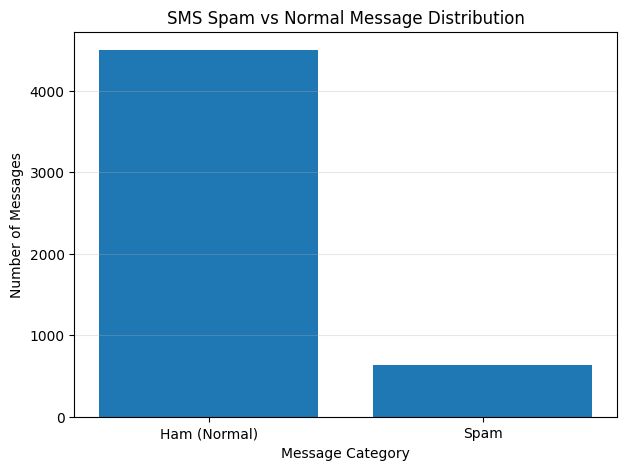

Class Distribution:
Ham: 4499
Spam: 631


In [8]:
# Step 3.4: Visualize Class Distribution

label_counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Ham (Normal)", "Spam"],
    label_counts.values
)

plt.title("SMS Spam vs Normal Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.grid(axis="y", alpha=0.3)
plt.show()

print("Class Distribution:")
print("Ham:", label_counts[0])
print("Spam:", label_counts[1])

In [9]:
# Step 4.1: Separate Features and Labels

X = df["cleaned_message"]
y = df["label"]

print("Input features separated successfully!")

print("\nTotal messages:", len(X))
print("Total labels:", len(y))

print("\nSample input messages:")
print(X.head())

print("\nSample output labels:")
print(y.head())

Input features separated successfully!

Total messages: 5130
Total labels: 5130

Sample input messages:
0    go until jurong point crazy available only in ...
1                              ok lar joking wif u oni
2    free entry in 2 a wkly comp to win fa cup fina...
3          u dun say so early hor u c already then say
4    nah i dont think he goes to usf he lives aroun...
Name: cleaned_message, dtype: object

Sample output labels:
0    0
1    0
2    1
3    0
4    0
Name: label, dtype: int64


In [10]:
# Step 4.2: Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset split completed!")

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Dataset split completed!

Training samples: 4104
Testing samples: 1026

Training class distribution:
label
0    3599
1     505
Name: count, dtype: int64

Testing class distribution:
label
0    900
1    126
Name: count, dtype: int64


In [11]:
# Step 4.3: TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Vectorization completed!")

print("\nTraining feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

print("\nSample vocabulary:")
print(list(tfidf.vocabulary_.keys())[:20])

TF-IDF Vectorization completed!

Training feature shape: (4104, 3000)
Testing feature shape: (1026, 3000)

Sample vocabulary:
['forgot', 'ask', 'smth', 'theres', 'card', 'da', 'present', 'lei', 'want', 'write', 'sign', 'ugh', 'ppl', 'dont', 'cds', '4u', 'congratulations', 'ur', 'awarded', '500']


In [12]:
# Step 5.1: Convert TF-IDF Data into PyTorch Tensors

X_train_dense = X_train_tfidf.toarray()
X_test_dense = X_test_tfidf.toarray()

X_train_tensor = torch.tensor(
    X_train_dense, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_dense, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.values, dtype=torch.float32
).view(-1, 1)

y_test_tensor = torch.tensor(
    y_test.values, dtype=torch.float32
).view(-1, 1)

print("PyTorch tensor conversion completed!")

print("\nTraining input shape:", X_train_tensor.shape)
print("Testing input shape:", X_test_tensor.shape)

print("\nTraining label shape:", y_train_tensor.shape)
print("Testing label shape:", y_test_tensor.shape)

PyTorch tensor conversion completed!

Training input shape: torch.Size([4104, 3000])
Testing input shape: torch.Size([1026, 3000])

Training label shape: torch.Size([4104, 1])
Testing label shape: torch.Size([1026, 1])


In [13]:
# Step 5.2: Build Deep Learning Neural Network

class SpamClassifier(nn.Module):

    def __init__(self, input_size):
        super(SpamClassifier, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)


input_size = X_train_tensor.shape[1]

model = SpamClassifier(input_size)

print("Neural Network created successfully!")

print("\nModel Architecture:")
print(model)

print("\nTotal Parameters:",
      sum(p.numel() for p in model.parameters()))

Neural Network created successfully!

Model Architecture:
SpamClassifier(
  (network): Sequential(
    (0): Linear(in_features=3000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=1, bias=True)
  )
)

Total Parameters: 802049


In [14]:
# Step 5.3: Configure Loss Function and Optimizer

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Loss function configured:", criterion)
print("Optimizer configured:", optimizer)

print("\nLearning Rate: 0.001")
print("Weight Decay: 0.00001")
print("Model configuration completed successfully!")

Loss function configured: BCEWithLogitsLoss()
Optimizer configured: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)

Learning Rate: 0.001
Weight Decay: 0.00001
Model configuration completed successfully!


In [15]:
# Step 6.1: Create Training and Validation Sets

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_tensor,
    y_train_tensor,
    test_size=0.1,
    random_state=42,
    stratify=y_train_tensor.numpy()
)

print("Training and validation split completed!")

print("\nTraining samples:", len(X_train_final))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test_tensor))

Training and validation split completed!

Training samples: 3693
Validation samples: 411
Testing samples: 1026


In [16]:
# Step 6.2: Create PyTorch DataLoaders

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    X_train_final, y_train_final
)

val_dataset = TensorDataset(
    X_val, y_val
)

test_dataset = TensorDataset(
    X_test_tensor, y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("DataLoaders created successfully!")

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!

Training batches: 58
Validation batches: 7
Testing batches: 17


In [17]:
# Step 6.3: Training and Validation Functions

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in loader:

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * inputs.size(0)

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def validate_model(model, loader, criterion):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for inputs, labels in loader:

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * inputs.size(0)

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = total_loss / total
    val_accuracy = correct / total

    return val_loss, val_accuracy


print("Training and validation functions created successfully!")

Training and validation functions created successfully!


In [18]:
# Step 6.4: Model Training with Early Stopping

num_epochs = 30
patience = 5

best_val_loss = float("inf")
counter = 0

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_model_state = None

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc = validate_model(
        model, val_loader, criterion
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        counter = 0

        best_model_state = {
            key: value.detach().clone()
            for key, value in model.state_dict().items()
        }

    else:

        counter += 1

    if counter >= patience:

        print("\nEarly stopping triggered!")
        break


model.load_state_dict(best_model_state)

print("\nTraining completed successfully!")
print("Best Validation Loss:", round(best_val_loss, 4))

Epoch [1/30] Train Loss: 0.2815 Train Acc: 0.9263 Val Loss: 0.1964 Val Acc: 0.9319
Epoch [2/30] Train Loss: 0.0721 Train Acc: 0.9900 Val Loss: 0.0837 Val Acc: 0.9854
Epoch [3/30] Train Loss: 0.0345 Train Acc: 0.9968 Val Loss: 0.0682 Val Acc: 0.9854
Epoch [4/30] Train Loss: 0.0226 Train Acc: 0.9973 Val Loss: 0.0616 Val Acc: 0.9854
Epoch [5/30] Train Loss: 0.0142 Train Acc: 0.9989 Val Loss: 0.0558 Val Acc: 0.9854
Epoch [6/30] Train Loss: 0.0103 Train Acc: 0.9995 Val Loss: 0.0551 Val Acc: 0.9830
Epoch [7/30] Train Loss: 0.0077 Train Acc: 0.9989 Val Loss: 0.0598 Val Acc: 0.9854
Epoch [8/30] Train Loss: 0.0073 Train Acc: 0.9992 Val Loss: 0.0570 Val Acc: 0.9830
Epoch [9/30] Train Loss: 0.0061 Train Acc: 0.9992 Val Loss: 0.0580 Val Acc: 0.9805
Epoch [10/30] Train Loss: 0.0064 Train Acc: 0.9992 Val Loss: 0.0531 Val Acc: 0.9805
Epoch [11/30] Train Loss: 0.0062 Train Acc: 0.9992 Val Loss: 0.0565 Val Acc: 0.9805
Epoch [12/30] Train Loss: 0.0049 Train Acc: 0.9995 Val Loss: 0.0589 Val Acc: 0.9805
E

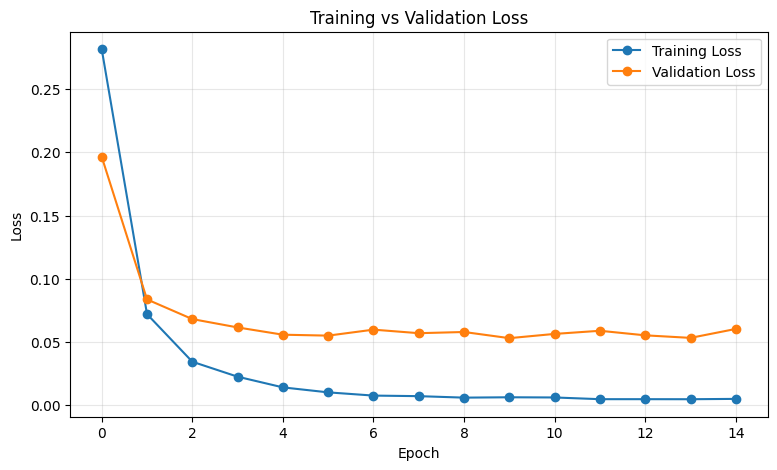

Loss convergence curve generated successfully!


In [19]:
# Step 7.1: Training and Validation Loss Curves

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss", marker="o")
plt.plot(val_losses, label="Validation Loss", marker="o")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

print("Loss convergence curve generated successfully!")

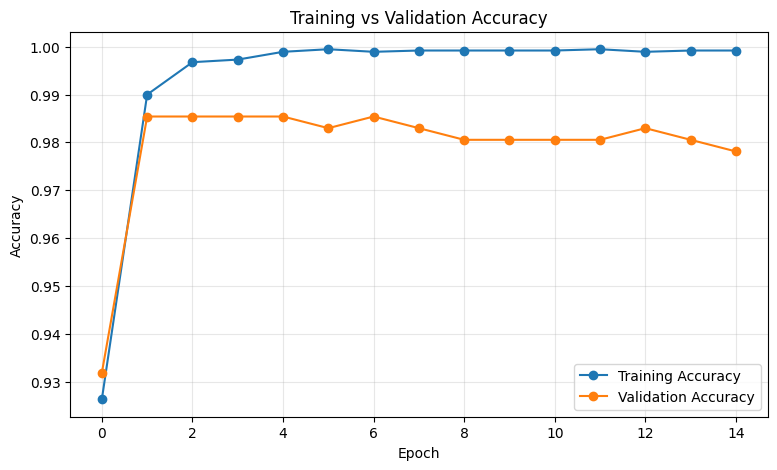

Accuracy convergence curve generated successfully!


In [20]:
# Step 7.2: Training and Validation Accuracy Curves

plt.figure(figsize=(9, 5))

plt.plot(
    train_accuracies,
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy",
    marker="o"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

print("Accuracy convergence curve generated successfully!")

In [21]:
# Step 8.1: Evaluate Model on Test Dataset

test_loss, test_accuracy = validate_model(
    model,
    test_loader,
    criterion
)

print("Model Evaluation Completed!")

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

print("\nCorrect Predictions:",
      int(test_accuracy * len(y_test_tensor)))

print("Total Test Samples:", len(y_test_tensor))

Model Evaluation Completed!

Test Loss: 0.0701
Test Accuracy: 97.76 %

Correct Predictions: 1003
Total Test Samples: 1026


In [22]:
# Step 8.2: Classification Report

model.eval()

all_predictions = []
all_actuals = []

with torch.no_grad():

    for inputs, labels in test_loader:

        outputs = model(inputs)

        predictions = (
            torch.sigmoid(outputs) >= 0.5
        ).int()

        all_predictions.extend(
            predictions.numpy().flatten()
        )

        all_actuals.extend(
            labels.numpy().flatten()
        )

print("Classification Report:\n")

print(
    classification_report(
        all_actuals,
        all_predictions,
        target_names=["Ham (Normal)", "Spam"]
    )
)

Classification Report:

              precision    recall  f1-score   support

Ham (Normal)       0.99      0.98      0.99       900
        Spam       0.89      0.93      0.91       126

    accuracy                           0.98      1026
   macro avg       0.94      0.96      0.95      1026
weighted avg       0.98      0.98      0.98      1026



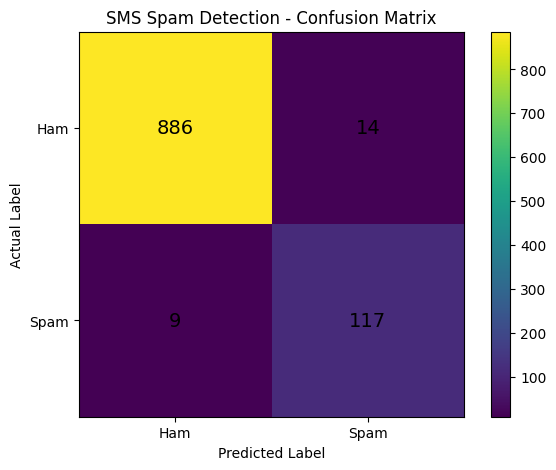

Confusion Matrix:
[[886  14]
 [  9 117]]


In [23]:
# Step 8.3: Confusion Matrix

cm = confusion_matrix(
    all_actuals,
    all_predictions
)

plt.figure(figsize=(7, 5))

plt.imshow(cm, interpolation="nearest")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.colorbar()

plt.xticks(
    [0, 1],
    ["Ham", "Spam"]
)

plt.yticks(
    [0, 1],
    ["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.show()

print("Confusion Matrix:")
print(cm)

In [24]:
# Step 9.1: Create SMS Prediction Function

def predict_sms(message):

    # Clean input message
    cleaned = clean_text(message)

    # Convert message into TF-IDF features
    vectorized = tfidf.transform([cleaned])

    # Convert into PyTorch tensor
    input_tensor = torch.tensor(
        vectorized.toarray(),
        dtype=torch.float32
    )

    # Model prediction
    model.eval()

    with torch.no_grad():

        output = model(input_tensor)

        spam_probability = torch.sigmoid(output).item()

    # Classification
    if spam_probability >= 0.5:
        prediction = "SPAM"
        confidence = spam_probability * 100
    else:
        prediction = "HAM (NORMAL)"
        confidence = (1 - spam_probability) * 100

    print("\nSMS Message:", message)
    print("Prediction:", prediction)
    print("Confidence:", round(confidence, 2), "%")


print("SMS prediction function created successfully!")

SMS prediction function created successfully!


In [25]:
# Step 9.2: Test Unseen SMS Messages

test_messages = [
    "Congratulations! You have won a free iPhone. Claim your prize now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have won a cash prize. Call now to claim!",
    "Your assignment submission is tomorrow. Please complete it.",
    "FREE entry in a weekly competition. Text WIN to 80086!",
    "I will reach home in 10 minutes."
]

for message in test_messages:
    predict_sms(message)
    print("-" * 60)


SMS Message: Congratulations! You have won a free iPhone. Claim your prize now!
Prediction: SPAM
Confidence: 99.95 %
------------------------------------------------------------

SMS Message: Hey, are we meeting for lunch today?
Prediction: HAM (NORMAL)
Confidence: 99.15 %
------------------------------------------------------------

SMS Message: URGENT! You have won a cash prize. Call now to claim!
Prediction: SPAM
Confidence: 99.95 %
------------------------------------------------------------

SMS Message: Your assignment submission is tomorrow. Please complete it.
Prediction: HAM (NORMAL)
Confidence: 99.68 %
------------------------------------------------------------

SMS Message: FREE entry in a weekly competition. Text WIN to 80086!
Prediction: SPAM
Confidence: 98.79 %
------------------------------------------------------------

SMS Message: I will reach home in 10 minutes.
Prediction: HAM (NORMAL)
Confidence: 99.92 %
-----------------------------------------------------------

In [26]:
# Step 9.3: Interactive SMS Spam Detector

while True:

    message = input("\nEnter an SMS message (or type 'exit' to stop): ")

    if message.lower() == "exit":
        print("SMS Spam Detector closed!")
        break

    if not message.strip():
        print("Please enter a valid message!")
        continue

    predict_sms(message)


Enter an SMS message (or type 'exit' to stop): Congratulations! You won a free gift.

SMS Message: Congratulations! You won a free gift.
Prediction: SPAM
Confidence: 94.8 %

Enter an SMS message (or type 'exit' to stop): exit
SMS Spam Detector closed!


In [27]:
# Step 10.1: Save Trained PyTorch Model

torch.save(
    model.state_dict(),
    "sms_spam_classifier.pth"
)

print("Trained model saved successfully!")
print("File: sms_spam_classifier.pth")

Trained model saved successfully!
File: sms_spam_classifier.pth


In [28]:
# Step 10.2: Save TF-IDF Vectorizer

import joblib

joblib.dump(
    tfidf,
    "sms_tfidf_vectorizer.pkl"
)

print("TF-IDF Vectorizer saved successfully!")
print("File: sms_tfidf_vectorizer.pkl")

TF-IDF Vectorizer saved successfully!
File: sms_tfidf_vectorizer.pkl


In [29]:
# Step 10.3: Download Project Files

from google.colab import files

files.download("sms_spam_classifier.pth")

files.download("sms_tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>